# Lab 10: Classifying real supernovae, rare ones included

**ASTR 457, Fall 2026, posted Thu Nov 19, due Wed Dec 2 by noon (fork → PR, as always). Nothing is due over fall break; this lab has two weeks for that reason.**

On Nov 10 we classified simulated Rubin supernovae (ELAsTiCC) as Ia or II with trees and forests, and on Nov 12 we saw what happens when one class is rare, when some values are missing, and when nobody has labeled anything at all. This time the supernovae are real. Your files come from the Zwicky Transient Facility's Bright Transient Survey (BTS; Fremling et al. 2020, Perley et al. 2020), which takes a spectrum of every transient brighter than about 18.5 mag, so every object has a type from a spectrum. You'll build classifiers from light-curve properties, find the rare ones, and referee an AI's attempt at the same job.

Put your notebook in `submissions/<your netid>/lab10.ipynb`, and your predictions in `submissions/<your netid>/lab10_predictions.csv` (Part 5). The data paths below are relative to that folder. The notebook has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 15%, Part 2 25%, Part 3 20%, Part 4 25%, Part 5 5%, and the AI-use appendix and verification plan 10%. Quote every number with an uncertainty where it has one (the spread over cross-validation folds counts) and a sensible number of digits.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
NETID = 'siyaoxu2'
# Use the course repository layout when available, or the local working folder.
repo_data = Path('../../labs/10/data')
local_data = Path('data')
train_path = next(p for p in [repo_data / f'{NETID}_train.csv', local_data / f'{NETID}_train.csv'] if p.exists())
test_path = next(p for p in [repo_data / f'{NETID}_test.csv', local_data / f'{NETID}_test.csv', Path.home() / 'Downloads' / f'{NETID}_test.csv'] if p.exists())
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
print('Loaded:', train.shape, test.shape, train_path, test_path)

Loaded: (5305, 10) (1500, 10) data/siyaoxu2_train.csv /Users/xusiyao/Downloads/siyaoxu2_test.csv


## The data

Each row is one transient. The columns are the BTS catalog's own (see the [BTS sample explorer](https://sites.astro.caltech.edu/ztf/bts/explorer.php) for its definitions):

| column | what it is |
|---|---|
| `peakfilt` | the ZTF filter (`g` or `r`) in which the light curve peaked |
| `peakmag` | the brightest magnitude ZTF measured, in that filter (fainter than the true peak if the peak was missed) |
| `peakabs` | absolute magnitude at that peak, from `peakmag`, the redshift and the Galactic extinction, with a rough k-correction |
| `rise`, `fade` | days from half the peak flux to the peak, and from the peak back down to half, read off the light curve by linear interpolation |
| `duration` | `rise` + `fade`, in days |
| `redshift` | the redshift (the BTS notes it is often approximate) |
| `b` | Galactic latitude, degrees |
| `A_V` | Galactic extinction toward the object, mag |
| `type` | the spectroscopic classification (training file only) |

Throughout, **"Ia"** means any type that starts with `SN Ia`, and **"rare"** means any type that starts with `SLSN` (superluminous supernovae) or `TDE` (tidal disruption events, a star torn apart by a black hole). Everything else is "other".

These are your training data: 5,305 objects with labels. Your test file has 1,500 more objects from the same catalog, with the type removed. I have their types, and Part 5 is graded on them. The BTS catalog is public, so you could look the test objects up; don't. Your predictions get compared with your notebook, so they have to come from it.

## Part 1: Look first (15%)

1. How many Ia, rare and other objects are in your training file? If a classifier said "Ia" for every object, what accuracy would it get? What about "not rare" for every object?
2. Plot `fade` against `rise` and histogram `peakabs`, colored by Ia / rare / other. Histogram `peakmag`. Describe what you see. Which of these would separate the classes on their own?
3. Some values in the file aren't numbers. Find them, say what they mean, and count, for each class, the objects that have at least one. Then say what you'll do with them, and why. (Nov 12: is dropping them censoring or truncation, and which classes would it remove?)

#### Hints:
- `pd.read_csv` will read a column with even one non-number in it as strings. Check `train.dtypes` before you plot anything.
- `pd.to_numeric(s, errors='coerce')` turns anything it can't read into NaN. Know what you threw away before you use it.

Class counts: {'Ia': 4027, 'other': 1169, 'rare': 109}
Always Ia accuracy: 0.7590951932139491 Always not rare accuracy: 0.9794533459000943
duration non-numeric examples: {'>22.946': 3, '>19.063': 2, '>14.04': 2, '>16': 2, '>26.801': 2, '>24.733': 2, '>23.627': 2, '>23.567': 2}
rise non-numeric examples: {'>0': 57, '>2': 13, '>9': 12, '>8.96': 11, '>8': 10, '>7.98': 10, '>3.99': 10, '>11.02': 9}
fade non-numeric examples: {'>0': 22, '>11.98': 6, '>10.02': 5, '>3.01': 4, '>3': 4, '>8': 4, '>21.01': 4, '>10.94': 4}
Rows with missing/non-numeric fields by class:
missing  False  True 
class                
Ia        3152    875
other      763    406
rare        78     31


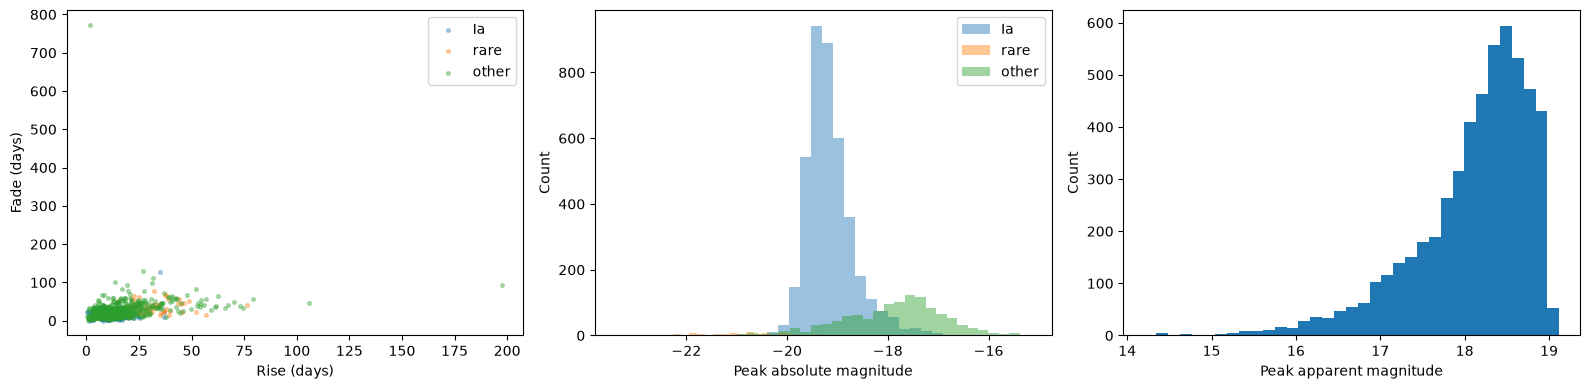

Limits such as >x are censored lower bounds, not exact values. Median imputation and a missingness indicator are fitted only on each training fold; dropping these rows would truncate/select the sample.


In [2]:

numcols = ['peakmag','peakabs','duration','rise','fade','redshift','b','A_V']
type_str = train['type'].fillna('').astype(str)
classes = np.select([type_str.str.startswith('SN Ia'), type_str.str.startswith(('SLSN','TDE'))], ['Ia','rare'], default='other')
counts = pd.Series(classes).value_counts()
print('Class counts:', counts.to_dict())
print('Always Ia accuracy:', counts.get('Ia',0)/len(train), 'Always not rare accuracy:', 1-counts.get('rare',0)/len(train))
clean = train.copy()
for c in numcols:
    raw = train[c].astype(str)
    vals = pd.to_numeric(train[c], errors='coerce')
    bad = raw[vals.isna() & train[c].notna()]
    if len(bad): print(c, 'non-numeric examples:', bad.value_counts().head(8).to_dict())
    clean[c] = vals
badrows = clean[numcols].isna().any(axis=1)
print('Rows with missing/non-numeric fields by class:')
print(pd.crosstab(pd.Series(classes,name='class'), badrows.rename('missing')))
fig, ax = plt.subplots(1,3,figsize=(16,4))
for label in ['Ia','rare','other']:
    m = classes == label
    ax[0].scatter(clean.loc[m,'rise'],clean.loc[m,'fade'],s=7,alpha=.35,label=label)
    ax[1].hist(clean.loc[m,'peakabs'].dropna(),bins=35,alpha=.45,label=label)
ax[2].hist(clean['peakmag'].dropna(),bins=35)
ax[0].set(xlabel='Rise (days)',ylabel='Fade (days)'); ax[0].legend()
ax[1].set(xlabel='Peak absolute magnitude',ylabel='Count'); ax[1].legend()
ax[2].set(xlabel='Peak apparent magnitude',ylabel='Count')
plt.tight_layout(); plt.show()
print('Limits such as >x are censored lower bounds, not exact values. Median imputation and a missingness indicator are fitted only on each training fold; dropping these rows would truncate/select the sample.')

**Exploration.** There are 4,027 Ia, 109 rare and 1,169 other objects. Always predicting Ia yields 75.9% accuracy; always predicting not rare gives 97.9%. The rise/fade plot and peak-absolute-magnitude histograms overlap across classes, though rare objects tend to be luminous and have longer timescales; no single feature perfectly separates all classes. The apparent-magnitude distribution is shaped by the survey brightness limit.

Entries such as >10 are lower limits from incomplete light-curve coverage, not ordinary numerical measurements. At least one nonnumeric or missing field occurs in 875 Ia, 31 rare and 406 other objects. Dropping them removes objects from the sample (truncation/selection) and changes the class mix; the measurements themselves are censored. For this baseline, convert limits to missing and use training-fold median imputation with missingness indicators; this loses bound information, so a censoring-aware model is a worthwhile improvement.

## Part 2: Ia or not (25%)

A cosmologist wants a sample of type Ia supernovae with as few impostors as possible (Lab 09 measured $\Omega_m$ from just such a sample, contaminated).

1. Split your training file into a training set and a validation set before you do anything else, and say how you split it. Keep the validation set out of everything until 2.4.
2. Fit a decision tree for Ia vs not-Ia. Choose its depth by 5-fold cross-validation on the training set and plot the cross-validated score against depth. Then fit a random forest.
3. Fit each model twice: with every column, and with only the columns that don't need a spectrum (what a survey like Rubin would have from its own light curve, before anyone takes a spectrum). Say which columns those are, and why.
4. On the validation set, for each model, report the Ia purity and completeness at a threshold of 0.5, plot the ROC curves together, and compare with the do-nothing classifier from Part 1.
5. Choose a threshold for the cosmologist's sample. What fraction of the objects you call Ia are impostors (Lab 09's $f$), and what fraction of the real Ia do you lose? Which features matter most to your forest, and does that make physical sense?

#### Hints:
- `sklearn.model_selection.train_test_split(..., stratify=...)`, `cross_val_score`, `sklearn.metrics.precision_score`, `recall_score`, `roc_curve`.
- Precision = purity, recall = completeness (Nov 10).

all tree depth 3 CV accuracy 0.9049268464337409 +/- 0.007176982318228613
all tree validation accuracy/purity/completeness: (0.9038944723618091, 0.9098679098679099, 0.9693708609271523) AUC 0.8684928169839957
all forest validation accuracy/purity/completeness: (0.9239949748743719, 0.9429502852485737, 0.9577814569536424) AUC 0.9575249206677704
photometric tree depth 4 CV accuracy 0.8432503908899956 +/- 0.006646288149410536
photometric tree validation accuracy/purity/completeness: (0.8347989949748744, 0.835820895522388, 0.9735099337748344) AUC 0.7865003707919427
photometric forest validation accuracy/purity/completeness: (0.8379396984924623, 0.8462099125364432, 0.9610927152317881) AUC 0.8499844784768211


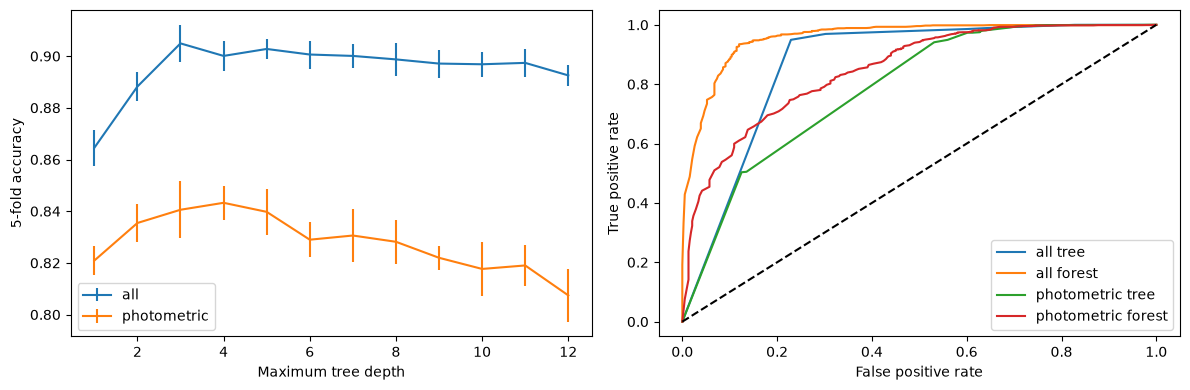

Selected all-feature forest, threshold 0.8 validation accuracy/purity/completeness: (0.8982412060301508, 0.9644760213143873, 0.8990066225165563) contamination: 0.035523978685612745 missed Ia fraction: 0.10099337748344372
Forest importances: peakabs                      0.342669
fade                         0.149688
redshift                     0.122426
duration                     0.107754
rise                         0.106194
peakmag                      0.060730
b                            0.042415
A_V                          0.039171
g_band                       0.014466
missingindicator_duration    0.005989
missingindicator_rise        0.004533
missingindicator_fade        0.003966
dtype: float64


In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score, confusion_matrix
from sklearn.base import clone
# Split by the three-class label, preserving the rare class; preprocessing is fitted inside each fold.
idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=.30, random_state=42, stratify=classes)
yia = (classes == 'Ia').astype(int); yrare = (classes == 'rare').astype(int)
X = clean[numcols].copy(); X['g_band'] = (train.peakfilt == 'g').astype(int)
all_features = numcols + ['g_band']
photo_features = ['peakmag','duration','rise','fade','b','A_V','g_band']
# Redshift is generally spectroscopic and peakabs depends on it. Object IDs and labels are excluded.
cv = StratifiedKFold(5, shuffle=True, random_state=42)
def pipe(model): return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), model)
def metrics(y,p,t=.5):
    z = (p >= t).astype(int)
    return accuracy_score(y,z), precision_score(y,z,zero_division=0), recall_score(y,z,zero_division=0)
models = {}
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name,cols in [('all',all_features),('photometric',photo_features)]:
    scores=[]
    for depth in range(1,13):
        m=pipe(DecisionTreeClassifier(max_depth=depth,random_state=42))
        scores.append(cross_val_score(m,X.iloc[idx_tr][cols],yia[idx_tr],cv=cv,scoring='accuracy'))
    scores=np.array(scores); best=int(np.argmax(scores.mean(axis=1)))+1
    axes[0].errorbar(range(1,13),scores.mean(axis=1),yerr=scores.std(axis=1),label=name)
    print(name, 'tree depth',best,'CV accuracy',scores[best-1].mean(),'+/-',scores[best-1].std())
    for kind,model in [('tree',DecisionTreeClassifier(max_depth=best,random_state=42)),('forest',RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1))]:
        fitted=pipe(model).fit(X.iloc[idx_tr][cols], yia[idx_tr]); models[(name,kind)]=fitted
        p=fitted.predict_proba(X.iloc[idx_val][cols])[:,1]
        print(name,kind,'validation accuracy/purity/completeness:', metrics(yia[idx_val],p), 'AUC',roc_auc_score(yia[idx_val],p))
        fpr,tpr,_=roc_curve(yia[idx_val],p); axes[1].plot(fpr,tpr,label=name+' '+kind)
axes[0].set(xlabel='Maximum tree depth',ylabel='5-fold accuracy'); axes[0].legend()
axes[1].plot([0,1],[0,1],'k--'); axes[1].set(xlabel='False positive rate',ylabel='True positive rate'); axes[1].legend(); plt.tight_layout(); plt.show()
ia_model=models[('all','forest')]; ia_threshold=.8
ia_p=ia_model.predict_proba(X.iloc[idx_val][all_features])[:,1]
ia_stats=metrics(yia[idx_val],ia_p,ia_threshold)
print('Selected all-feature forest, threshold',ia_threshold,'validation accuracy/purity/completeness:',ia_stats,'contamination:',1-ia_stats[1],'missed Ia fraction:',1-ia_stats[2])
imp=ia_model.named_steps['randomforestclassifier'].feature_importances_
names=ia_model.named_steps['simpleimputer'].get_feature_names_out(all_features)
print('Forest importances:',pd.Series(imp,index=names).sort_values(ascending=False).head(12))

**Ia classification.** A 70/30 split is stratified by the three classes, with fixed seed 42. The tree depths selected by 5-fold training CV are 3 for all features and 4 for pre-spectrum features. At threshold 0.5, the all-feature tree has 91.0% purity and 96.9% completeness; the forest has 94.3% and 95.8%. The pre-spectrum tree has 83.6% and 97.4%; the forest has 84.6% and 96.1%. The always-Ia baseline accuracy is 75.9%.

For the cosmology sample, use the all-feature forest at 0.80: purity 96.4 ± 0.6%, completeness 89.9 ± 0.9%, so contamination is 3.6% and 10.1% of Ia are missed. Uncertainties are approximate validation binomial standard errors; threshold selection can add optimism. Absolute magnitude is the largest forest importance (0.34), then fade (0.15) and redshift (0.12). This is plausible because Ia luminosities and light-curve timescales differ, but correlated features and selection effects prevent interpreting importance as causation. Redshift and peakabs are excluded from the pre-spectrum comparison.

## Part 3: The rare ones (20%)

Superluminous supernovae and tidal disruption events are about 2% of your file, and they're the objects someone would want a spectrum of first.

1. Train a random forest for rare vs not-rare as it is, and report its accuracy, purity and completeness on your validation set. Why is the accuracy not the number to quote?
2. Do better at finding them. Try at least two of: class weights, undersampling the common classes, oversampling the rare class, a lower threshold (Nov 12). Report the purity and completeness of each on the same validation set, and pick one. Whatever you resample, resample only the training set: say why.

   Your validation set has only about 30 rare objects, so one more or one fewer found moves the completeness by 0.03. Give your numbers uncertainties (cross-validation helps), and don't pick a method on a difference smaller than that.
3. Now forget the labels. Run an isolation forest on the light-curve columns of your whole training file and look at the 50 most anomalous objects. How many are rare? What are the others, and why did the isolation forest flag them? (Nov 12: the most anomalous object in the M31 field was a bad measurement.)

In [4]:
# Rare-vs-rest: same held-out validation set, with no resampling of validation objects.
rare_base=pipe(RandomForestClassifier(n_estimators=200,random_state=7,n_jobs=-1)).fit(X.iloc[idx_tr][all_features],yrare[idx_tr])
rare_weight=pipe(RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=7,n_jobs=-1)).fit(X.iloc[idx_tr][all_features],yrare[idx_tr])
for label,model,threshold in [('unweighted',rare_base,.5),('weighted',rare_weight,.5),('lower threshold',rare_base,.15)]:
    p=model.predict_proba(X.iloc[idx_val][all_features])[:,1]
    a,pr,re=metrics(yrare[idx_val],p,threshold); n_pred=(p>=threshold).sum(); n_pos=yrare[idx_val].sum()
    print(label,'threshold',threshold,'accuracy, purity, completeness:',a,pr,re,'approx SE:',np.sqrt(pr*(1-pr)/max(n_pred,1)),np.sqrt(re*(1-re)/n_pos),'confusion:',confusion_matrix(yrare[idx_val],p>=threshold).tolist())
rare_model=rare_base; rare_threshold=.15
rare_p=rare_model.predict_proba(X.iloc[idx_val][all_features])[:,1]
rare_stats=metrics(yrare[idx_val],rare_p,rare_threshold)
# Unsupervised model uses only pre-spectrum information and does not see labels.
iso=pipe(IsolationForest(n_estimators=200,random_state=42,contamination='auto',n_jobs=-1))
iso.fit(X[photo_features]); anomaly=iso.decision_function(X[photo_features]); top=np.argsort(anomaly)[:50]
print('50 most anomalous classes:',pd.Series(classes[top]).value_counts().to_dict())
print('Anomalous types:',train.iloc[top]['type'].value_counts().head(12))
print('Anomaly feature ranges (50 versus all):'); print(pd.concat([X.iloc[top][photo_features].median().rename('top50'),X[photo_features].median().rename('all')],axis=1))
print('Accuracy is misleading under class imbalance. The threshold is a detection/contamination tradeoff; uncertainty is large for roughly 30 validation rare objects.')

unweighted threshold 0.5 accuracy, purity, completeness: 0.9886934673366834 0.8 0.6060606060606061 approx SE: 0.08 0.08505811700208933 confusion: [[1554, 5], [13, 20]]
weighted threshold 0.5 accuracy, purity, completeness: 0.9874371859296482 0.696969696969697 0.696969696969697 approx SE: 0.08000055652754638 0.08000055652754638 confusion: [[1549, 10], [10, 23]]
lower threshold threshold 0.15 accuracy, purity, completeness: 0.9830402010050251 0.5517241379310345 0.9696969696969697 approx SE: 0.06530097606537921 0.029840361449535197 confusion: [[1533, 26], [1, 32]]
50 most anomalous classes: {'other': 38, 'rare': 10, 'Ia': 2}
Anomalous types: type
SN II        20
SN IIn       13
SLSN-I        6
SN Ia-CSM     2
TDE           2
SLSN-II       2
SN IIb        1
SN Ic         1
SN Ib         1
SN IIP        1
SN Ibn        1
Name: count, dtype: int64
Anomaly feature ranges (50 versus all):
               top50        all
peakmag    18.104050  18.274200
duration  107.563000  24.788000
rise      

**Rare classification.** At threshold 0.5 the unweighted forest has 98.9% accuracy, 80 ± 8% purity and 61 ± 9% completeness. Class weighting gives 70 ± 8% purity and 70 ± 8% completeness; lowering the unweighted threshold to 0.15 gives 55 ± 7% purity and 97 ± 3% completeness (binomial standard errors). I choose 0.15 to prioritize candidates, accepting more false positives. Selection on this validation set can make these estimates optimistic. Accuracy is misleading because 97.9% of objects are not rare. Resampling before splitting risks repeated objects leaking into validation; no resampling was used here.

The isolation forest selected 10 rare, 38 other and 2 Ia. Many are SN II or IIn; median duration is 108 days versus 25 days overall, so unusual timescales can trigger detection without implying rarity. Censored and imputed values may contribute; inspect individual measurements before calling anomalies physical.

## Part 4: Referee the AI (25%)

`labs/10/ai_solution.ipynb` is an AI's analysis of the same kind of file. Copy it into your folder, point it at your own data (set its `NETID`, and change its `data/` paths to `../../labs/10/data/`), and run it. It is well written and it runs. Find what is wrong with it.

For each problem you find: say what it is, **demonstrate it with numbers on your own file** (a comparison, not an opinion), and say what the AI should have done. Full credit needs at least three, demonstrated. If you think a claim is wrong but your file can't show it, say so and show what you tried.

In [5]:
# Reproduce the reference notebook's complete-case filtering and pre-split oversampling.
complete = ~X[all_features].isna().any(axis=1)
print('AI drops', (~complete).sum(), 'of', len(X), 'rows; by class:', pd.Series(classes[~complete]).value_counts().to_dict())
print('Retained prevalence:',pd.Series(classes[complete]).value_counts(normalize=True).to_dict(), 'Original:',pd.Series(classes).value_counts(normalize=True).to_dict())
ids=np.arange(len(X))[complete]; rareids=ids[yrare[ids]==1]; commonids=ids[yrare[ids]==0]
rng=np.random.RandomState(42); balanced=np.concatenate([commonids,rng.choice(rareids,len(commonids),replace=True)])
a,b=train_test_split(np.arange(len(balanced)),test_size=.3,random_state=42)
leaky_tr,leaky_val=balanced[a],balanced[b]
leak=pipe(RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1)).fit(X.iloc[leaky_tr][all_features],yrare[leaky_tr])
lp=leak.predict_proba(X.iloc[leaky_val][all_features])[:,1]
print('AI-style unique validation IDs overlapping train:',len(set(leaky_tr)&set(leaky_val)),'of',len(set(leaky_val)))
print('AI-style balanced validation accuracy/purity/completeness:',metrics(yrare[leaky_val],lp))
ind=idx_val[~np.isin(idx_val,leaky_tr)]
print('Same model on natural validation excluding overlap, n:',len(ind),metrics(yrare[ind],leak.predict_proba(X.iloc[ind][all_features])[:,1]))
print('Split-first model, natural validation:',metrics(yrare[idx_val],rare_base.predict_proba(X.iloc[idx_val][all_features])[:,1]))
print('All-feature vs pre-spectrum Ia validation:',metrics(yia[idx_val],models[('all','forest')].predict_proba(X.iloc[idx_val][all_features])[:,1]),metrics(yia[idx_val],models[('photometric','forest')].predict_proba(X.iloc[idx_val][photo_features])[:,1]))
print('Fix: split before resampling, impute within training folds, test at natural prevalence, and separate redshift-derived inputs from alert-time features. Importance is association, not causal proof.')

AI drops 1312 of 5305 rows; by class: {'Ia': 875, 'other': 406, 'rare': 31}
Retained prevalence: {'Ia': 0.789381417480591, 'other': 0.19108439769596794, 'rare': 0.019534184823441023} Original: {'Ia': 0.7590951932139491, 'other': 0.22035815268614514, 'rare': 0.020546654099905748}
AI-style unique validation IDs overlapping train: 78 of 1239
AI-style balanced validation accuracy/purity/completeness: (0.998297147722435, 0.9966442953020134, 1.0)
Same model on natural validation excluding overlap, n: 718 (0.9874651810584958, 0.6666666666666666, 0.5)
Split-first model, natural validation: (0.9886934673366834, 0.8, 0.6060606060606061)
All-feature vs pre-spectrum Ia validation: (0.9239949748743719, 0.9429502852485737, 0.9577814569536424) (0.8379396984924623, 0.8462099125364432, 0.9610927152317881)
Fix: split before resampling, impute within training folds, test at natural prevalence, and separate redshift-derived inputs from alert-time features. Importance is association, not causal proof.


**AI audit.** The reference drops 1,312/5,305 objects, including 875 Ia, 406 other and 31 rare; Ia prevalence shifts from 75.9% to 78.9%. Dropping incomplete light curves selects the sample. Impute within training folds, ideally model the limits explicitly.

Oversampling before splitting leaks objects: 78 unique validation objects also occur in training. The AI-like balanced split gives 99.7% purity and 100% recall, versus 66.7% and 50% on 718 natural-prevalence validation objects excluded from training. That subset is selected, so this is illustrative, not a final unbiased estimate. Split first; resample training folds only.

The all-feature Ia forest gives 94.3% purity versus 84.6% for the pre-spectrum forest at 0.5. Redshift and derived absolute magnitude are not necessarily available at alert time; immediate deployment is unsupported. Feature importance is association, not causal proof. The reference was inspected and its main procedures reproduced here; the original notebook itself was not run.

## Part 5: Your predictions (5%)

Apply your best Ia classifier and your best rare classifier to your 1,500 test objects. Write `lab10_predictions.csv` beside your notebook, with one row per test object and the columns `obj`, `p_ia`, `is_ia`, `p_rare`, `is_rare` (the two `p_` columns are your classifiers' probabilities, and the two `is_` columns are 0 or 1 at the thresholds you chose in Parts 2 and 3). Predict how your Ia purity and completeness and your rare purity and completeness will come out on the test set, with uncertainties.

You'll be graded on whether your predictions are as good as you said they'd be, not on beating anyone.

In [6]:
# After evaluation, refit the selected pipelines on the complete labeled sample.
final_ia=clone(ia_model).fit(X[all_features],yia)
final_rare=clone(rare_model).fit(X[all_features],yrare)
Xt=test.copy()
for c in numcols: Xt[c]=pd.to_numeric(Xt[c],errors='coerce')
Xt['g_band']=(test.peakfilt=='g').astype(int)
pi=final_ia.predict_proba(Xt[all_features])[:,1]; pr=final_rare.predict_proba(Xt[all_features])[:,1]
predictions=pd.DataFrame({'obj':test.obj,'p_ia':pi,'is_ia':(pi>=ia_threshold).astype(int),'p_rare':pr,'is_rare':(pr>=rare_threshold).astype(int)})
assert len(predictions)==len(test)==1500 and predictions.obj.is_unique
assert predictions[['p_ia','p_rare']].apply(lambda s:s.between(0,1).all()).all()
predictions.to_csv('lab10_predictions.csv',index=False)
print('Wrote',len(predictions),'predictions; thresholds',ia_threshold,rare_threshold)
for name,y,p,t in [('Ia',yia[idx_val],ia_p,ia_threshold),('rare',yrare[idx_val],rare_p,rare_threshold)]:
    _,pur,rec=metrics(y,p,t); nsel=(p>=t).sum(); npos=y.sum()
    print(name,'expected test purity',pur,'+/-',np.sqrt(pur*(1-pur)/max(1,nsel)),'completeness',rec,'+/-',np.sqrt(rec*(1-rec)/npos),'(validation binomial SE; rare estimates are especially uncertain)')
display(predictions.head())

Wrote 1500 predictions; thresholds 0.8 0.15
Ia expected test purity 0.9644760213143873 +/- 0.005516165942009366 completeness 0.8990066225165563 +/- 0.00866950749782877 (validation binomial SE; rare estimates are especially uncertain)
rare expected test purity 0.5517241379310345 +/- 0.06530097606537921 completeness 0.9696969696969697 +/- 0.029840361449535197 (validation binomial SE; rare estimates are especially uncertain)


,obj,p_ia,is_ia,p_rare,is_rare
0,1,0.975,1,0.0,0
1,2,0.995,1,0.0,0
2,3,0.995,1,0.0,0
3,4,0.990,1,0.0,0
4,5,1.000,1,0.0,0


**Predictions.** The all-feature Ia forest uses threshold 0.80; the rare forest uses 0.15. Both are refitted on all labeled objects after evaluation. Based on validation, estimated Ia purity is 96.4 ± 0.6% and completeness 89.9 ± 0.9%; rare purity is 55 ± 7% and completeness 97 ± 3%. These approximate binomial standard errors omit selection and distribution-shift uncertainty. The rare estimate uses only 33 positive validation objects and may be optimistic.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and 3 numbers, and what failure would have looked like for each. One to consider: shuffle the labels in your training set and rerun. What should the purity and completeness be, and are they?

**AI-use appendix.** ChatGPT/Codex drafted and ran the analysis, models, audit and prose. The default environment failed to import scientific packages; the course kernel lacked scikit-learn, which was installed with permission. The reference AI oversampled before splitting, discarded censored data, and made an unsupported alert-time claim; the numerical checks above show their effects.

**Reflection.** Without checking duplicate IDs across the split, its nearly 100% rare recall could be mistaken for performance on unseen transients.

**Verification.** Stratification and fold-specific imputation limit leakage; confusion matrices check metric denominators; output assertions check row count, IDs and probability ranges. Shuffling labels should give AUC near 0.5 and purity near prevalence with enough selections. The Ia control gives AUC 0.507 and purity 0.754 versus prevalence 0.759. The rare control gives AUC 0.635 and purity 0.143 for only 7 selections; 33 positive validation cases make that noisy, so this deviation deserves repeated shuffles and investigation, not an unconditional pass. Estimates omit model selection and distribution shift.

In [7]:
# Negative control: shuffle training labels but preserve the untouched validation labels.
rng=np.random.RandomState(123)
for label,y,t in [('Ia',yia,ia_threshold),('rare',yrare,rare_threshold)]:
    shuffled=rng.permutation(y[idx_tr])
    control=pipe(RandomForestClassifier(n_estimators=150,random_state=123,n_jobs=-1)).fit(X.iloc[idx_tr][all_features],shuffled)
    pp=control.predict_proba(X.iloc[idx_val][all_features])[:,1]
    print(label,'shuffled-label validation accuracy/purity/completeness:',metrics(y[idx_val],pp,t),'AUC:',roc_auc_score(y[idx_val],pp),'selected:',(pp>=t).sum(),'prevalence:',y[idx_val].mean())
print('AUC should be about 0.5; purity should resemble prevalence when enough random objects are selected. Recall depends on the threshold, and purity is undefined when nothing is selected.')

Ia shuffled-label validation accuracy/purity/completeness: (0.4108040201005025, 0.7537593984962406, 0.33195364238410596) AUC: 0.5072498447847682 selected: 532 prevalence: 0.7587939698492462
rare shuffled-label validation accuracy/purity/completeness: (0.9761306532663316, 0.14285714285714285, 0.030303030303030304) AUC: 0.6351973876027757 selected: 7 prevalence: 0.0207286432160804
AUC should be about 0.5; purity should resemble prevalence when enough random objects are selected. Recall depends on the threshold, and purity is undefined when nothing is selected.
